# Plot a map with the footprints of the RFI-affected products

Plot the footprints of the products selected in the data loading. Footpritns are color coded with a metric extracted from the RFI stats to identify the regions highly affected by RFI.

In [6]:
%pip install aiohttp requests
%load_ext autoreload
%autoreload 2
    
from shapely.geometry import shape, mapping
import matplotlib.pyplot as plt
from folium import GeoJson
import geopandas as gpd
import pandas as pd
import numpy as np
import folium
import json
import yaml
from pathlib import Path
import branca.colormap as cm
import antimeridian
from processing import pol_mean

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
# Load the config.yaml to access the paths
cfg_file = Path("../config.yaml").resolve()
cfg = yaml.safe_load(cfg_file.read_text())

# Set the name of the path in the config.yaml
token_path = (cfg_file.parent / cfg["paths"]["token_file"]).resolve()
out_path = (cfg_file.parent / cfg["paths"]["output"]).resolve()
rfi_prod_path = out_path / cfg["files"]["rfi_products"]
gdf_path = out_path / cfg["files"]["gdf"]

output_map_name = "rfi_footprints_map.html"

print(f"Token Path: {token_path}")
print(f"Output Path: {out_path}")
print(f"List of RFI products Path: {rfi_prod_path}")
print(f"GeoDataframe of RFI products Path: {gdf_path}")

Token Path: /home/amelis/projects/BIOMASS/token.txt
Output Path: /home/amelis/projects/BIOMASS/biomass-hackathon-2026/topics/02-rfi-removal/out
List of RFI products Path: /home/amelis/projects/BIOMASS/biomass-hackathon-2026/topics/02-rfi-removal/out/products_rfi_clean.json
GeoDataframe of RFI products Path: /home/amelis/projects/BIOMASS/biomass-hackathon-2026/topics/02-rfi-removal/out/gdf_clean.parquet


In [8]:
# Load the list of products affected by RFI
with open(rfi_prod_path) as f:
    products_rfi = json.load(f)
    
# Load the GeoDataframe
gdf = gpd.read_parquet(gdf_path)

gdf.head()

,index,product_id,start_datetime,end_datetime,geometry
0,0,BIO_S2_SCS__1S_20260701T123811_20260701T123832...,2026-07-01T12:38:11.831Z,2026-07-01T12:38:32.232Z,"POLYGON ((81.36048 -12.21592, 81.94188 -12.331..."
1,1,BIO_S2_SCS__1S_20260701T123752_20260701T123813...,2026-07-01T12:37:52.816Z,2026-07-01T12:38:13.217Z,"POLYGON ((81.60335 -11.06099, 82.18138 -11.176..."
2,2,BIO_S2_SCS__1S_20260701T123733_20260701T123754...,2026-07-01T12:37:33.803Z,2026-07-01T12:37:54.202Z,"POLYGON ((81.84579 -9.90591, 82.42077 -10.0217..."
3,3,BIO_S2_SCS__1S_20260701T123714_20260701T123735...,2026-07-01T12:37:14.790Z,2026-07-01T12:37:35.188Z,"POLYGON ((82.08812 -8.75062, 82.66066 -8.86677..."
4,4,BIO_S2_SCS__1S_20260701T123655_20260701T123716...,2026-07-01T12:36:55.777Z,2026-07-01T12:37:16.174Z,"POLYGON ((82.33027 -7.59519, 82.89998 -7.71159..."


Read the products_rfi.json and the geo dataframes created in the data loading notebook. Impact is the product of the polarisation-averaged percentage of affected azimuth lines and the polarisation-averaged percentage of range bandwidth affected, i.e. an estimate of the percentage of the azimuth-time × range-frequency plane contaminated by RFI.

In [9]:
rfi_ids = {p["id"] : p for p in products_rfi}

# --- 1. One row per product: footprint + RFI attributes (unflagged products keep NaN)
rows = [{"product_id": p["id"], "rfiCorrectionFlag": p["rfiCorrectionFlag"], **p["properties"], **p["fm"]}
        for p in products_rfi]
# Convert the products_rfi list into a dataframe
df_rfi = pd.DataFrame(rows) if rows else pd.DataFrame(columns=["product_id"])
# Merge it with the previous geo dataframe
gdf_rfi = gdf[["product_id", "start_datetime", "end_datetime", "geometry"]].merge(
    df_rfi, on="product_id", how="left")
gdf_rfi["rfiDetected"] = gdf_rfi["product_id"].isin(rfi_ids)
gdf_rfi["geometry"] = gdf_rfi.geometry.apply(lambda g: shape(antimeridian.fix_shape(mapping(g))))

# --- 2. Impact metric per RFI type (kind = "pers" or "iso")
#   avgBW    = mean over polarisations of the average % bandwidth affected
#   linesPct = mean over polarisations of the % of affected lines
#   impact   = avgBW * linesPct / 100   (~ % of the line x bandwidth plane that is affected)

for kind in ("pers", "iso"):
    gdf_rfi[f"{kind}_avgBW"] = pol_mean(gdf_rfi, kind, "avgBW")
    gdf_rfi[f"{kind}_linesPct"] = pol_mean(gdf_rfi, kind, "linesPct")
    gdf_rfi[f"{kind}_impact"] = gdf_rfi[f"{kind}_avgBW"] * gdf_rfi[f"{kind}_linesPct"] / 100
    df_rfi[f"{kind}_impact"] = gdf_rfi[f"{kind}_avgBW"] * gdf_rfi[f"{kind}_linesPct"] / 100

# --- 3. Interactive map with a persistent / isolated selector (LayerControl radio buttons)
layers = {"Persistent FM RFI": "pers", "Isolated FM RFI": "iso"}

vmax = max([float(gdf_rfi[f"{k}_impact"].max()) for k in layers.values()
            if gdf_rfi[f"{k}_impact"].notna().any()] + [1.0])           # same scale for both layers
print(vmax)
# cmap = cm.LinearColormap(["#ffffe5",  "#bd0026"], vmin=0, vmax=vmax,
#                          caption="RFI impact = avg % BW x % affected lines / 100")
cmap = cm.linear.YlOrRd_09.scale(0, vmax)

def make_style(kind):
    def style(feat):
        v = feat["properties"].get(f"{kind}_impact")
        if v is None or v != v:                                      # no RFI / no report -> grey
            return {"color": "dimgray", "weight": 1, "fillColor": "lightgray", "fillOpacity": 0.25}
        return {"color": "black", "weight": 0.0, "fillColor": cmap(v), "fillOpacity": 0.65}
    return style

minx, miny, maxx, maxy = gdf_rfi.total_bounds
m_rfi = folium.Map(location=[(miny + maxy) / 2, (minx + maxx) / 2], tiles=None, zoom_start=3)
folium.TileLayer("OpenStreetMap", control=False).add_to(m_rfi)
# folium.TileLayer("CartoDB positron", control=False).add_to(m_rfi)
for i, (label, kind) in enumerate(layers.items()):
    g = gdf_rfi[["product_id", "rfiDetected", "geometry",
                 f"{kind}_avgBW", f"{kind}_linesPct", f"{kind}_impact"]].copy()
    g[[f"{kind}_avgBW", f"{kind}_linesPct", f"{kind}_impact"]] = \
        g[[f"{kind}_avgBW", f"{kind}_linesPct", f"{kind}_impact"]].round(2)
    GeoJson(
        g.__geo_interface__,
        name=label,
        overlay=False,                                               # radio button: one layer at a time
        show=(i == 0),
        tooltip=folium.GeoJsonTooltip(fields=["product_id", "rfiDetected",
                                              f"{kind}_avgBW", f"{kind}_linesPct", f"{kind}_impact"]),
        style_function=make_style(kind),
    ).add_to(m_rfi)

# --- 4. Overlay: products with rfiCorrectionFlag == False (checkbox, on top of the radio layers)
no_corr = gdf_rfi[gdf_rfi["rfiCorrectionFlag"].astype(str).str.lower() == "false"]
print(f"{len(no_corr)} products with rfiCorrectionFlag=False")

if len(no_corr):  # folium's tooltip asserts on an empty layer
    GeoJson(
        no_corr[["product_id", "pers_impact", "iso_impact", "geometry"]].round(2).__geo_interface__,
        name=f"correctionFlag = False ({len(no_corr)})",
        overlay=True, show=False,
        style_function=lambda f: {"color": "blue", "weight": 3, "fillOpacity": 0},
        tooltip=folium.GeoJsonTooltip(fields=["product_id", "pers_impact", "iso_impact"]),
        popup=folium.GeoJsonPopup(fields=["product_id"]),                # click a footprint to copy its id
        zoom_on_click=True
    ).add_to(m_rfi)

selected_ids = no_corr["product_id"].tolist()                        # same selection for the download step
cmap.add_to(m_rfi)
folium.LayerControl(collapsed=False).add_to(m_rfi)
m_rfi.fit_bounds([[miny, minx], [maxy, maxx]])
# m_rfi.save(str(out_path / output_map_name))                # standalone copy
m_rfi

65.44464119555103
30 products with rfiCorrectionFlag=False


NameError: name 'gdf_rfi' is not defined

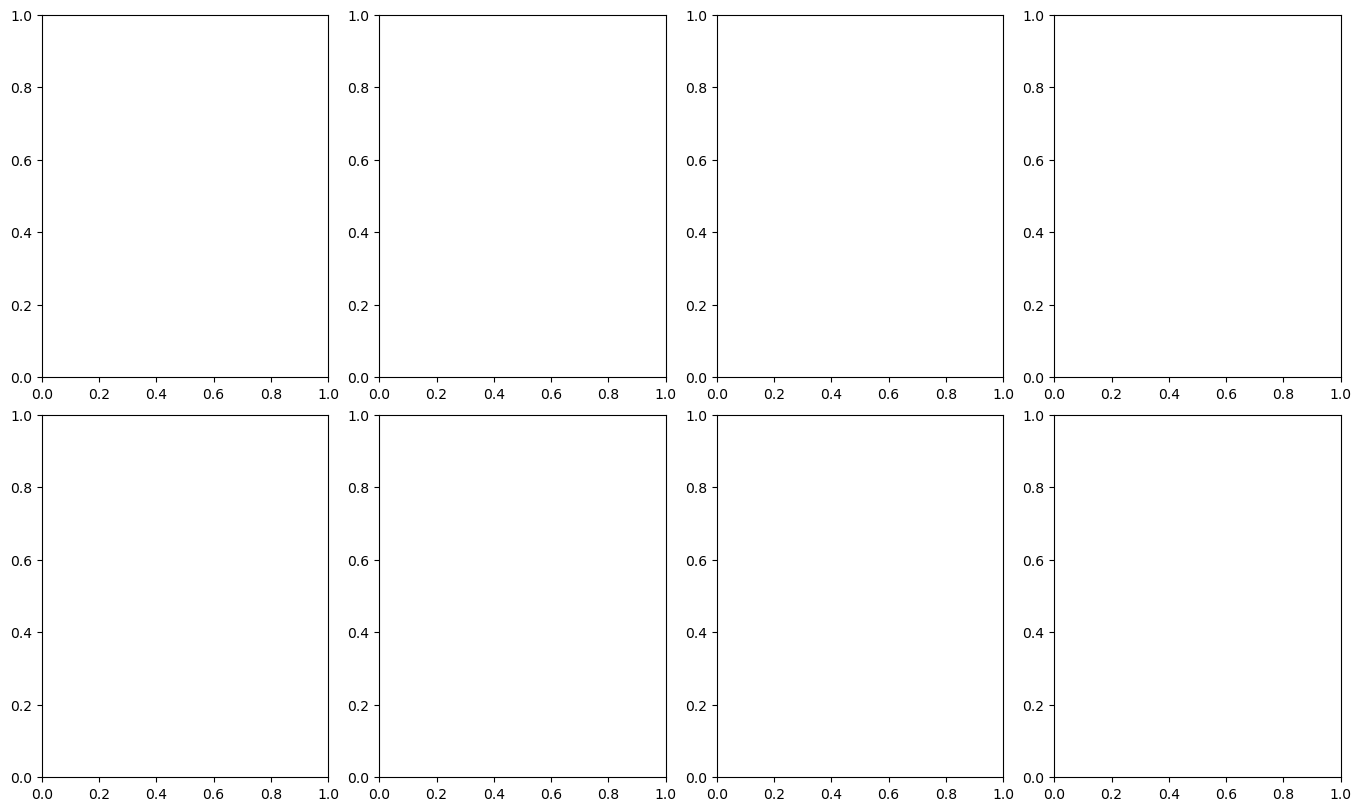

In [5]:
POLS  = ["HH", "HV", "VH", "VV"]
KINDS = ["iso", "pers"]
STATS = ["avgBW", "linesPct", "maxBW", "impact"]

fig, axd = plt.subplot_mosaic(
    [[f"{k}_{s}" for s in STATS] for k in KINDS],
    figsize=(4.5 * 3, 8), constrained_layout=True,
)
for k in KINDS:
    for s in STATS:
        ax = axd[f"{k}_{s}"]
        if s == "impact":
            cols = [f"{k}_impact"]                                   # already averaged over pols
        else:
            cols = [f"{k}_{p}_{s}" for p in POLS]
        cols = [c for c in cols if c in gdf_rfi]
        vals = gdf_rfi[cols].stack() if cols else pd.Series(dtype=float)   # all pols, for shared bins
        if vals.dropna().empty:
            ax.set_title(f"{k} {s} (no data)"); continue
        bins = np.histogram_bin_edges(vals.dropna(), bins=30)
        for c in cols:
            ax.hist(gdf_rfi[c].dropna(), bins=bins, alpha=0.5,
                    label="mean" if s == "impact" else c.split("_")[1])
        ax.set_title(f"{k} {s}")
        ax.set_xlabel({"impact": "impact (avg % BW x % lines / 100)"}.get(
            s, "% of bandwidth" if "BW" in s else "% of lines"))
        ax.set_yscale("log")
        ax.legend()
plt.show()